# Customer Churn Analysis

### Telco Customer Churn | Python, Pandas, Seaborn & Statistical Analysis

**Objective:** Identify customer segments associated with higher churn and translate the findings into actionable business recommendations.

## 1. Project Overview

Customer churn is an important business problem because losing existing customers can affect recurring revenue and increase customer acquisition costs.

This project analyzes customer churn using the Telco Customer Churn dataset to:

- Measure the overall churn rate
- Identify important churn patterns
- Analyze customer segments
- Statistically validate key relationships
- Identify a high-risk customer segment
- Develop data-driven retention recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, ttest_ind

## 2. Data Loading

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

## 3. Data Understanding

In [81]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 7043
Columns: 23
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   object  
 1   gender            7043 non-null   object  
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   object  
 4   Dependents        7043 non-null   object  
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   object  
 7   MultipleLines     7043 non-null   object  
 8   InternetService   7043 non-null   object  
 9   OnlineSecurity    7043 non-null   object  
 10  OnlineBackup      7043 non-null   object  
 11  DeviceProtection  7043 non-null   object  
 12  TechSupport       7043 non-null   object  
 13  StreamingTV       7043 non-null   object  
 14  StreamingMovies   7043 non-null   object  
 15  Contract          7043 non-null   object  
 16  P

df.columns

In [7]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


## 4. Data Cleaning

In [10]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [82]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [83]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TenureGroup         0
HighRiskSegment     0
dtype: int64

# 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to understand the distribution of customer churn and identify patterns associated with customer characteristics such as contract type, tenure, monthly charges, payment method, and internet service.

## 5.1 Overall Churn

In [84]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
churn_percentage

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

### Insight

The overall customer churn rate is **26.54%**, meaning approximately one in four customers in the dataset has churned.

This provides the baseline churn rate against which different customer segments can be compared.

## 5.2 Contract Type vs Churn

In [39]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize = "index"
) * 100

contract_churn
            

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


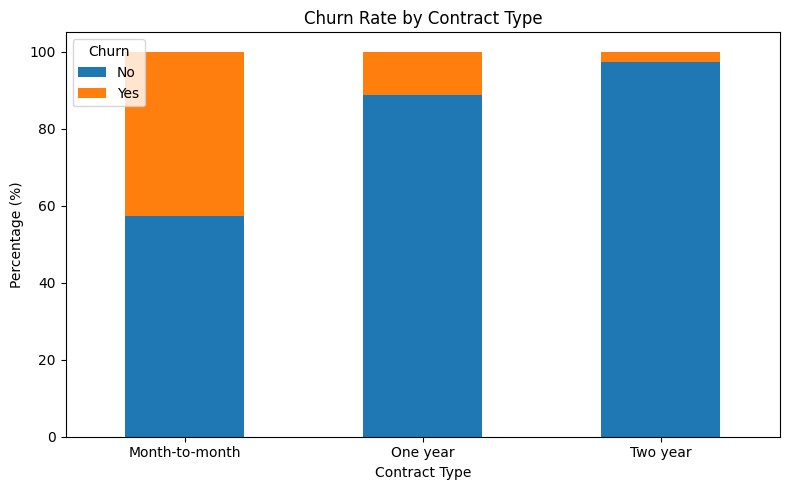

In [85]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

### Insight

Month-to-month customers have the highest observed churn rate at **42.71%**, compared with **11.27%** for one-year contracts and **2.83%** for two-year contracts.

This indicates a strong association between contract type and churn. The relationship was later validated using a chi-square test.

The analysis shows association rather than causation.

## 5.3 Tenure vs Churn

In [40]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [41]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-60 months", "61-72 months"]
)

In [42]:
df["TenureGroup"].value_counts().sort_index()

TenureGroup
0-12 months     2186
13-24 months    1024
25-48 months    1594
49-60 months     832
61-72 months    1407
Name: count, dtype: int64

In [43]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn

Churn,No,Yes
TenureGroup,,
0-12 months,52.561757,47.438243
13-24 months,71.289062,28.710938
25-48 months,79.611041,20.388959
49-60 months,85.576923,14.423077
61-72 months,93.390192,6.609808


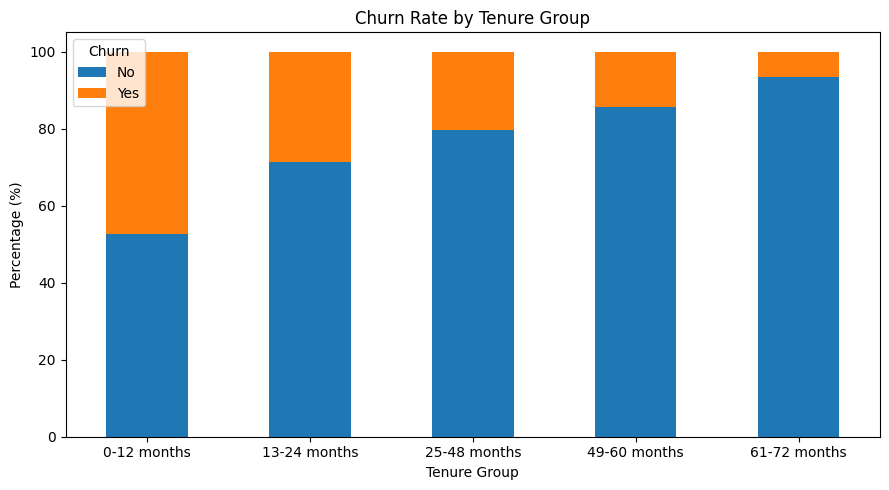

In [86]:
tenure_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

### Insight

Customers with **0–12 months of tenure** have the highest observed churn rate at **47.44%**.

Churn decreases progressively across the tenure groups, reaching **6.61%** among customers with 61–72 months of tenure.

This suggests that early customer tenure is an important area for retention analysis.

## 5.4 Monthly Charges vs Churn

In [45]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [46]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Churn,,,,
No,61.265124,64.425,18.25,118.75
Yes,74.441332,79.650,18.85,118.35


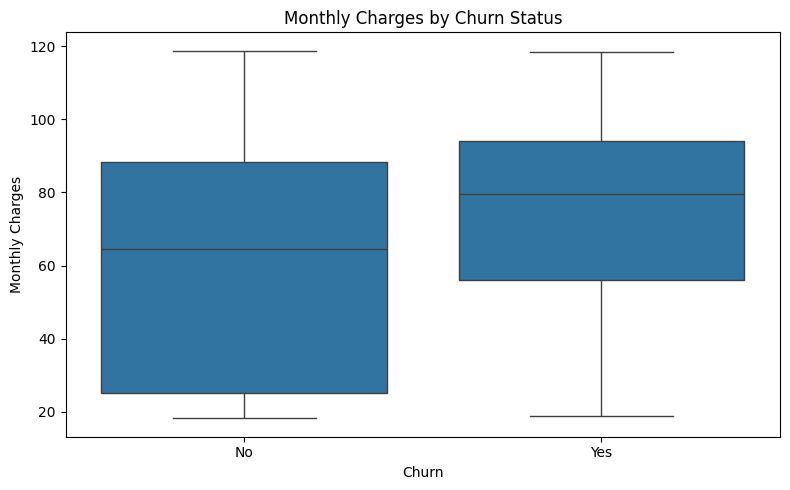

In [87]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Churn",
    y="MonthlyCharges",
    data=df
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

### Insight

Customers who churned have higher monthly charges on average than customers who remained.

The average monthly charge is **$74.44** for churned customers compared with **$61.27** for retained customers.

This difference is statistically significant based on the independent samples t-test performed later in the analysis.

However, the difference should be interpreted as an association rather than evidence that higher charges directly cause churn.

## 5.5 Payment Method vs Churn

In [48]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


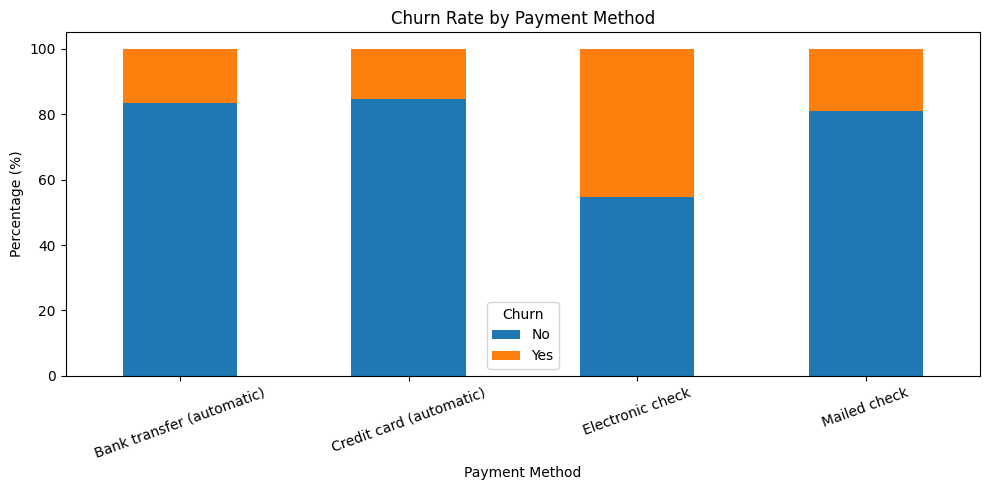

In [88]:
payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=20)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

### Insight

Customers using **electronic check** have the highest observed churn rate at **45.29%**.

Customers using automatic bank transfer and automatic credit card payments show substantially lower churn rates.

This indicates a strong association between payment method and churn, which is later validated using a chi-square test.

## 5.6 Internet Service vs Churn

In [129]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize = "index"
) * 100
internet_churn    

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


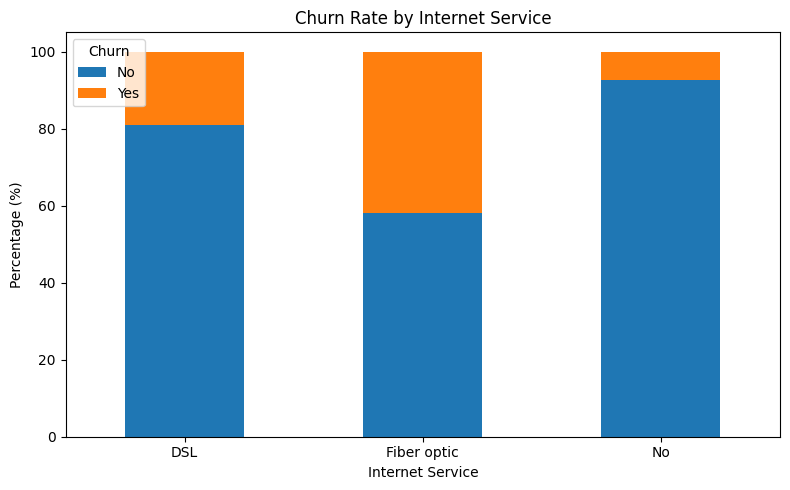

In [89]:
internet_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

### Insight

Customers with **Fiber optic service** have the highest observed churn rate at **41.89%**, compared with **18.96%** for DSL customers and **7.40%** for customers without internet service.

The relationship between Internet Service and churn is statistically significant based on the chi-square test performed later.

The analysis identifies an association and does not establish that the type of internet service itself causes churn.

## 5.7 EDA Summary

The exploratory analysis identified several notable patterns:

- Overall churn rate is **26.54%**.
- **Month-to-month customers** have substantially higher observed churn than customers on longer contracts.
- **Early-tenure customers** show the highest churn rates.
- Churned customers have **higher average monthly charges** than retained customers.
- **Electronic check** customers show elevated churn.
- **Fiber optic** customers show elevated churn.

These findings motivate a deeper customer segmentation analysis to identify combinations of characteristics associated with particularly high churn.

# 6. Customer Segmentation

Customer segmentation is used to identify groups of customers with similar characteristics and different levels of churn risk.

The analysis focuses on tenure, contract type, payment method, and internet service to identify customer segments with particularly high observed churn rates.

In [56]:
contract_tenure_churn = pd.crosstab(
    [df["Contract"], df["TenureGroup"]],
    df["Churn"],
    normalize="index"
) * 100

contract_tenure_churn

Churn                                No        Yes
Contract       TenureGroup                        
Month-to-month 0-12 months    48.645938  51.354062
               13-24 months   62.279512  37.720488
               25-48 months   67.082294  32.917706
               49-60 months   72.222222  27.777778
               61-72 months   77.777778  22.222222
One year       0-12 months    89.516129  10.483871
               13-24 months   91.878173   8.121827
               25-48 months   89.382239  10.617761
               49-60 months   86.292835  13.707165
               61-72 months   87.859425  12.140575
Two year       0-12 months   100.000000   0.000000
               13-24 months  100.000000   0.000000
               25-48 months   97.810219   2.189781
               49-60 months   96.028881   3.971119
               61-72 months   96.855984   3.144016

In [58]:
segment_analysis = df.groupby(
    ["Contract", "TenureGroup"],
    observed=True
).agg(
    Customers=("customerID", "count"),
    Churned=("Churn", lambda x: (x == "Yes").sum()),
    Churn_Rate=("Churn", lambda x: (x == "Yes").mean() * 100)
).reset_index()

segment_analysis.sort_values("Churn_Rate", ascending=False)

,Contract,TenureGroup,Customers,Churned,Churn_Rate
0,Month-to-month,0-12 months,1994,1024,51.354062
1,Month-to-month,13-24 months,737,278,37.720488
2,Month-to-month,25-48 months,802,264,32.917706
3,Month-to-month,49-60 months,234,65,27.777778
4,Month-to-month,61-72 months,108,24,22.222222
8,One year,49-60 months,321,44,13.707165
9,One year,61-72 months,313,38,12.140575
7,One year,25-48 months,518,55,10.617761
5,One year,0-12 months,124,13,10.483871
6,One year,13-24 months,197,16,8.121827


In [90]:
meaningful_segments = segment_analysis[
    segment_analysis["Customers"] >= 100
].sort_values(
    "Churn_Rate",
    ascending=False
)

meaningful_segments

,Contract,TenureGroup,Customers,Churned,Churn_Rate
0,Month-to-month,0-12 months,1994,1024,51.354062
1,Month-to-month,13-24 months,737,278,37.720488
2,Month-to-month,25-48 months,802,264,32.917706
3,Month-to-month,49-60 months,234,65,27.777778
4,Month-to-month,61-72 months,108,24,22.222222
8,One year,49-60 months,321,44,13.707165
9,One year,61-72 months,313,38,12.140575
7,One year,25-48 months,518,55,10.617761
5,One year,0-12 months,124,13,10.483871
6,One year,13-24 months,197,16,8.121827


In [91]:
df["EarlyMonthToMonth"] = np.where(
    (df["Contract"] == "Month-to-month") &
    (df["TenureGroup"] == "0-12 months"),
    "Month-to-month + 0-12 months",
    "Other"
)

In [92]:
df["EarlyMonthToMonth"].value_counts()

EarlyMonthToMonth
Other                           5049
Month-to-month + 0-12 months    1994
Name: count, dtype: int64

In [93]:
early_segment_churn = pd.crosstab(
    df["EarlyMonthToMonth"],
    df["Churn"],
    normalize="index"
) * 100

early_segment_churn

Churn,No,Yes
EarlyMonthToMonth,,
Month-to-month + 0-12 months,48.645938,51.354062
Other,83.264013,16.735987


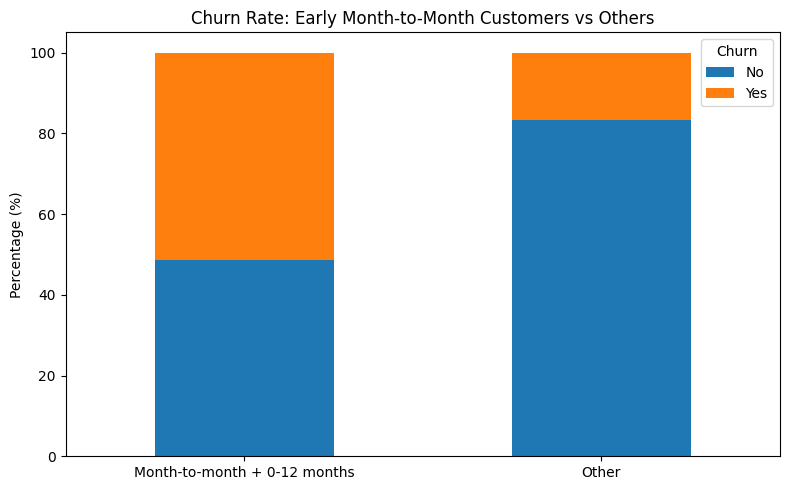

In [94]:
early_segment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate: Early Month-to-Month Customers vs Others")
plt.xlabel("")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [95]:
high_risk_df = df[
    (df["Contract"] == "Month-to-month") &
    (df["TenureGroup"] == "0-12 months")
].copy()

In [96]:
high_risk_payment = pd.crosstab(
    high_risk_df["PaymentMethod"],
    high_risk_df["Churn"],
    normalize="index"
) * 100

high_risk_payment

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),51.442308,48.557692
Credit card (automatic),58.638743,41.361257
Electronic check,36.897275,63.102725
Mailed check,62.246490,37.753510


In [97]:
high_risk_df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             954
Mailed check                 641
Bank transfer (automatic)    208
Credit card (automatic)      191
Name: count, dtype: int64

In [98]:
high_risk_internet = pd.crosstab(
    high_risk_df["InternetService"],
    high_risk_df["Churn"],
    normalize="index"
) * 100

high_risk_internet

Churn,No,Yes
InternetService,,
DSL,57.536232,42.463768
Fiber optic,29.803493,70.196507
No,77.319588,22.680412


In [99]:
payment_internet_churn = pd.crosstab(
    [
        high_risk_df["PaymentMethod"],
        high_risk_df["InternetService"]
    ],
    high_risk_df["Churn"],
    normalize="index"
) * 100

payment_internet_churn

Churn                                             No        Yes
PaymentMethod             InternetService                      
Bank transfer (automatic) DSL              73.417722  26.582278
                          Fiber optic      18.390805  81.609195
                          No               78.571429  21.428571
Credit card (automatic)   DSL              62.162162  37.837838
                          Fiber optic      38.666667  61.333333
                          No               88.095238  11.904762
Electronic check          DSL              49.645390  50.354610
                          Fiber optic      28.843106  71.156894
                          No               73.170732  26.829268
Mailed check              DSL              60.000000  40.000000
                          Fiber optic      37.398374  62.601626
                          No               76.045627  23.954373

In [100]:
df["FinalHighRiskSegment"] = np.where(
    (df["Contract"] == "Month-to-month") &
    (df["TenureGroup"] == "0-12 months") &
    (df["InternetService"] == "Fiber optic") &
    (df["PaymentMethod"] == "Electronic check"),
    "High-Risk Segment",
    "Other"
)

In [106]:
final_segment = df[
    df["FinalHighRiskSegment"] == "High-Risk Segment"
]

final_segment.shape

(631, 25)

In [107]:
final_segment["Churn"].value_counts()

Churn
Yes    449
No     182
Name: count, dtype: int64

In [108]:
final_segment["Churn"].value_counts(
    normalize=True
) * 100

Churn
Yes    71.156894
No     28.843106
Name: proportion, dtype: float64

In [109]:
final_segment_summary = pd.DataFrame({
    "Metric": [
        "Customers in Segment",
        "Churned Customers",
        "Retained Customers",
        "Churn Rate"
    ],
    "Value": [
        len(final_segment),
        (final_segment["Churn"] == "Yes").sum(),
        (final_segment["Churn"] == "No").sum(),
        f"{(final_segment['Churn'] == 'Yes').mean() * 100:.2f}%"
    ]
})

final_segment_summary

,Metric,Value
0,Customers in Segment,631
1,Churned Customers,449
2,Retained Customers,182
3,Churn Rate,71.16%


In [110]:
final_segment_churn = pd.crosstab(
    df["FinalHighRiskSegment"],
    df["Churn"],
    normalize="index"
) * 100

final_segment_churn

Churn,No,Yes
FinalHighRiskSegment,,
High-Risk Segment,28.843106,71.156894
Other,77.854024,22.145976


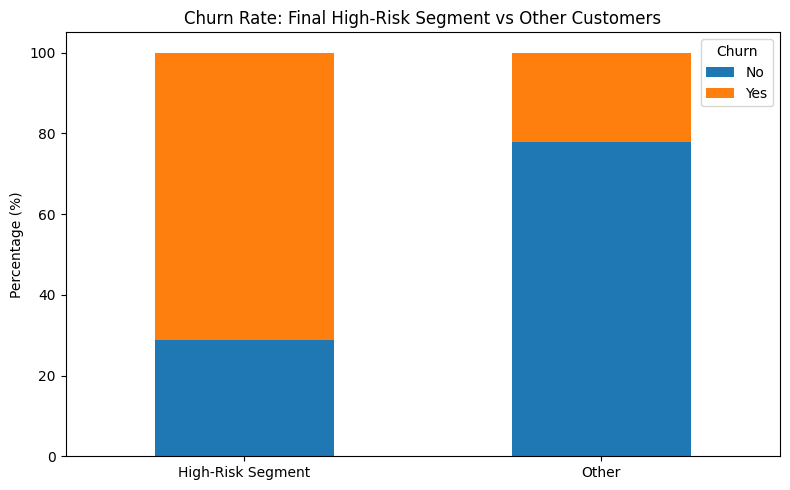

In [111]:
final_segment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate: Final High-Risk Segment vs Other Customers")
plt.xlabel("")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [112]:
segment_size = (
    df["FinalHighRiskSegment"]
    .value_counts(normalize=True)
    * 100
)

segment_size

FinalHighRiskSegment
Other                91.04075
High-Risk Segment     8.95925
Name: proportion, dtype: float64

## 6.17 Customer Segmentation Insights

The segmentation analysis identified a particularly high-risk customer group characterized by four attributes:

- Month-to-month contract
- 0–12 months of tenure
- Fiber optic internet service
- Electronic check payment method

This segment contains **631 customers**, of whom **449 have churned**, resulting in an observed churn rate of **71.16%**.

The segment is substantially smaller than the overall customer base but shows a much higher churn rate than the overall dataset churn rate of **26.54%**.

The analysis suggests that early-tenure month-to-month customers deserve particular attention, with payment method and internet service providing additional segmentation dimensions.

These relationships represent associations in the dataset and should not be interpreted as evidence that any individual characteristic directly causes churn.

# 8. Statistical Analysis

Statistical analysis is used to determine whether the relationships observed during exploratory data analysis are statistically significant.

Chi-square tests are used to examine associations between categorical variables and churn, while an independent samples t-test is used to compare monthly charges between churned and retained customers.

A statistically significant result indicates evidence of an association or difference in this dataset. It does not establish causation.

## 8.1 Chi-Square Test of Independence

The Chi-Square Test of Independence is used to determine whether two categorical variables are statistically associated.

For this project, the test is used to examine whether variables such as contract type, tenure group, payment method, and internet service are associated with customer churn.

### Hypotheses

**Null Hypothesis (H₀):**  
There is no association between the variable and customer churn.

**Alternative Hypothesis (H₁):**  
There is an association between the variable and customer churn.

A significance level of **0.05** is used.

- If p-value < 0.05 → reject H₀
- If p-value ≥ 0.05 → fail to reject H₀

A significant result indicates an association, not causation.

In [113]:
contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_table

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [114]:
chi2, p_value, dof, expected = chi2_contingency(
    contract_table
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 1184.5965720837926
p-value: 5.863038300673391e-258


### Interpretation

The p-value is far below **0.05**.

Therefore, we reject the null hypothesis that contract type and churn are independent.

There is strong statistical evidence of an association between **contract type and customer churn** in this dataset.

The EDA finding that month-to-month customers have substantially higher observed churn is therefore statistically significant.

However, the test does not establish that contract type itself causes churn.


In [115]:
tenure_table = pd.crosstab(
    df["TenureGroup"],
    df["Churn"]
)

tenure_table

Churn,No,Yes
TenureGroup,,
0-12 months,1149,1037
13-24 months,730,294
25-48 months,1269,325
49-60 months,712,120
61-72 months,1314,93


In [117]:
chi2, p_value, dof, expected = chi2_contingency(
    tenure_table
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 872.4724944206446
p-value: 1.5336320944401804e-187


### Interpretation

The p-value is far below **0.05**.

Therefore, we reject the null hypothesis that tenure group and churn are independent.

There is strong statistical evidence of an association between **customer tenure group and churn**.

This supports the EDA finding that customers in the early stages of their relationship with the company have higher observed churn rates.

The result indicates association rather than causation.

In [118]:
payment_table = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_table

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


chi2, p_value, dof, expected = chi2_contingency(
    payment_table
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

### Interpretation

The p-value is far below **0.05**.

Therefore, we reject the null hypothesis that payment method and churn are independent.

There is strong statistical evidence of an association between **payment method and customer churn**.

The EDA finding that electronic check customers have a higher observed churn rate is statistically significant in this dataset.

This result does not establish that payment method causes churn.

In [121]:
internet_table = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

internet_table

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [122]:
chi2, p_value, dof, expected = chi2_contingency(
    internet_table
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 732.309589667794
p-value: 9.571788222840544e-160


### Interpretation

The p-value is far below **0.05**.

Therefore, we reject the null hypothesis that internet service type and churn are independent.

There is strong statistical evidence of an association between **internet service and customer churn**.

The EDA finding that fiber optic customers have a higher observed churn rate is statistically significant in this dataset.

The test identifies an association and does not establish causation.

## 8.6 Why Chi-Square?

The Chi-Square Test of Independence is appropriate because both variables being tested are categorical.

For example:

- Contract → categorical
- Churn → categorical
- Payment Method → categorical
- Internet Service → categorical
- Tenure Group → categorical

The test evaluates whether the distribution of churn differs across categories of the variable being analyzed.

## 8.7 Independent Samples T-Test

An independent samples t-test is used to compare the average monthly charges of customers who churned with those who remained.

### Hypotheses

**Null Hypothesis (H₀):**  
The mean monthly charges are equal for churned and retained customers.

**Alternative Hypothesis (H₁):**  
The mean monthly charges are different between churned and retained customers.

A significance level of **0.05** is used.

In [123]:
churned_charges = df[
    df["Churn"] == "Yes"
]["MonthlyCharges"]

retained_charges = df[
    df["Churn"] == "No"
]["MonthlyCharges"]

In [124]:
t_stat, p_value = ttest_ind(
    churned_charges,
    retained_charges,
    equal_var=False
)

print("t-statistic:", t_stat)
print("p-value:", p_value)

t-statistic: 18.407526676414673
p-value: 8.592449331547067e-73


In [125]:
print(
    "Average monthly charge - Churned:",
    churned_charges.mean()
)

print(
    "Average monthly charge - Retained:",
    retained_charges.mean()
)

Average monthly charge - Churned: 74.44133226324237
Average monthly charge - Retained: 61.26512369540008


### Interpretation

The p-value is far below **0.05**.

Therefore, we reject the null hypothesis that churned and retained customers have the same average monthly charges.

There is strong statistical evidence of a difference in average monthly charges between the two groups.

Churned customers have an average monthly charge of approximately **$74.44**, compared with approximately **$61.27** for retained customers.

The difference is statistically significant, but statistical significance alone does not establish that higher monthly charges cause customers to churn.

In [126]:
statistical_summary = pd.DataFrame({
    "Test": [
        "Contract vs Churn",
        "Tenure Group vs Churn",
        "Payment Method vs Churn",
        "Internet Service vs Churn",
        "Monthly Charges vs Churn"
    ],
    "Test Type": [
        "Chi-Square",
        "Chi-Square",
        "Chi-Square",
        "Chi-Square",
        "Independent T-Test"
    ],
    "Statistic": [
        1184.5966,
        872.4725,
        648.1423,
        732.3096,
        18.4075
    ],
    "P-Value": [
        5.863e-258,
        1.534e-187,
        3.682e-140,
        9.572e-160,
        8.592e-73
    ],
    "Significant": [
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes"
    ]
})

statistical_summary

,Test,Test Type,Statistic,P-Value,Significant
0,Contract vs Churn,Chi-Square,1184.5966,5.863000e-258,Yes
1,Tenure Group vs Churn,Chi-Square,872.4725,1.534000e-187,Yes
2,Payment Method vs Churn,Chi-Square,648.1423,3.682000e-140,Yes
3,Internet Service vs Churn,Chi-Square,732.3096,9.572000e-160,Yes
4,Monthly Charges vs Churn,Independent T-Test,18.4075,8.592000e-73,Yes


In [127]:
statistical_summary["P-Value"] = statistical_summary["P-Value"].apply(
    lambda x: f"{x:.2e}"
)

statistical_summary

,Test,Test Type,Statistic,P-Value,Significant
0,Contract vs Churn,Chi-Square,1184.5966,5.86e-258,Yes
1,Tenure Group vs Churn,Chi-Square,872.4725,1.53e-187,Yes
2,Payment Method vs Churn,Chi-Square,648.1423,3.68e-140,Yes
3,Internet Service vs Churn,Chi-Square,732.3096,9.57e-160,Yes
4,Monthly Charges vs Churn,Independent T-Test,18.4075,8.59e-73,Yes


## 8.8 Statistical Analysis Summary

The statistical analysis provides strong evidence of associations between customer churn and several customer characteristics.

The Chi-Square tests found statistically significant associations between churn and:

- Contract type
- Tenure group
- Payment method
- Internet service

The independent samples t-test also found a statistically significant difference in average monthly charges between churned and retained customers.

These results strengthen the patterns identified during exploratory analysis.

However, statistical significance does not imply causation. The results indicate associations within this dataset and should be combined with business context before making retention decisions.

# 9. Business Insights & Recommendations

The analysis identified several customer characteristics associated with higher churn.

This section translates those findings into business insights and potential retention actions. The recommendations are based on observed patterns in the dataset and should be validated with additional customer and operational data before implementation.

## 9.1 Overall Churn

The overall customer churn rate is **26.54%**, meaning approximately one in four customers in the dataset has churned.

This indicates a meaningful customer retention challenge and provides the baseline against which individual customer segments can be evaluated.

## 9.2 Contract Type and Churn

Month-to-month customers have an observed churn rate of **42.71%**, substantially higher than customers with one-year contracts (**11.27%**) and two-year contracts (**2.83%**).

The Chi-Square test also found a statistically significant association between contract type and churn.

### Business Insight

Customers without a longer-term contract represent an important retention segment.

### Recommendation

The business could investigate targeted retention strategies for month-to-month customers, such as:

- Contract upgrade incentives
- Personalized retention offers
- Early-tenure engagement campaigns
- Clear communication of the benefits of longer-term plans

Any proposed incentive should be evaluated based on retention impact and profitability.

## 9.3 Early-Tenure Customers

Customers with **0–12 months of tenure** have the highest observed churn rate at **47.44%**.

Churn declines substantially as customer tenure increases, reaching **6.61%** among customers with 61–72 months of tenure.

The Chi-Square test also found a statistically significant association between tenure group and churn.

### Business Insight

The first year of the customer relationship appears to be a particularly important period for retention.

### Recommendation

The business could introduce a structured early-customer retention program, including:

- Onboarding follow-ups
- Service satisfaction checks
- Early issue resolution
- Usage guidance
- Targeted offers before the first-year milestone

The objective would be to identify dissatisfaction before customers reach the point of cancellation.

## 9.4 Payment Method and Churn

Customers using **electronic check** have the highest observed churn rate among the payment methods at **45.29%**.

The Chi-Square test found a statistically significant association between payment method and churn.

### Business Insight

Payment method may be useful as a customer segmentation variable when identifying customers for retention analysis.

### Recommendation

The business could investigate whether electronic-check customers experience differences in:

- Payment convenience
- Billing experience
- Payment failures
- Customer service interactions
- Payment preferences

If operational data supports the finding, the company could test whether encouraging convenient automatic payment options improves retention.

## 9.5 Internet Service and Churn

Fiber optic customers have an observed churn rate of **41.89%**, compared with **18.96%** for DSL customers and **7.40%** for customers without internet service.

The Chi-Square test found a statistically significant association between internet service type and churn.

### Business Insight

Fiber optic customers represent an important segment for further investigation.

### Recommendation

The business should investigate whether the elevated churn among fiber optic customers is related to factors such as:

- Service quality
- Pricing
- Technical issues
- Customer expectations
- Support experience
- Competitor offerings

Additional operational and customer-experience data would be required to determine the underlying drivers.

## 9.6 Monthly Charges and Churn

Customers who churned have an average monthly charge of approximately **$74.44**, compared with approximately **$61.27** for retained customers.

The independent samples t-test found a statistically significant difference between the two groups.

### Business Insight

Higher monthly charges are associated with churn in this dataset.

However, monthly charges may also reflect differences in services, plans, or customer characteristics.

### Recommendation

The business could investigate high-charge customers for:

- Pricing sensitivity
- Plan-value perception
- Service usage
- Competitor pricing
- Opportunities for better plan alignment

Retention offers should be evaluated carefully so that discounts do not unnecessarily reduce revenue from customers who would have remained anyway.

## 9.7 High-Risk Customer Segment

The segmentation analysis identified a high-risk customer segment characterized by:

- Month-to-month contract
- 0–12 months of tenure
- Fiber optic internet service
- Electronic check payment method

This segment contains **631 customers**, of whom **449 have churned**.

The observed churn rate for this segment is **71.16%**, substantially higher than the overall dataset churn rate of **26.54%**.

### Business Insight

This combination of customer characteristics provides a useful profile for targeted retention analysis.

The segment is large enough to be operationally relevant while showing a substantially elevated observed churn rate.

### Recommendation

The business could prioritize this segment for proactive retention analysis.

Potential actions include:

1. **Early-tenure engagement**
   - Contact customers during their first year.
   - Monitor early signs of dissatisfaction.

2. **Service experience review**
   - Investigate fiber optic service complaints and technical issues.

3. **Payment experience review**
   - Understand whether electronic-check customers experience different billing or payment issues.

4. **Contract strategy**
   - Test whether appropriate longer-term plan options improve retention.

5. **Targeted retention experiments**
   - Compare retention outcomes between customers receiving targeted interventions and similar customers who do not.

The goal should be to test which intervention improves retention without unnecessarily increasing retention costs.

## 9.8 Segment Size Matters

The analysis considered both **churn rate and customer volume** when identifying high-risk segments.

For example, the combination of month-to-month contract, early tenure, fiber optic service, and bank-transfer payment showed an observed churn rate above 80%, but the segment contained only **87 customers**.

By comparison, the electronic-check and fiber-optic combination contained **631 customers** and had a **71.16% observed churn rate**.

Therefore, the final segment was selected based on both elevated churn and meaningful customer volume rather than churn percentage alone.

In [128]:
business_summary = pd.DataFrame({
    "Finding": [
        "Overall churn",
        "Highest contract churn",
        "Highest tenure-group churn",
        "Highest payment-method churn",
        "Highest internet-service churn",
        "Final high-risk segment"
    ],
    "Result": [
        "26.54%",
        "Month-to-month: 42.71%",
        "0-12 months: 47.44%",
        "Electronic check: 45.29%",
        "Fiber optic: 41.89%",
        "71.16% churn"
    ]
})

business_summary

,Finding,Result
0,Overall churn,26.54%
1,Highest contract churn,Month-to-month: 42.71%
2,Highest tenure-group churn,0-12 months: 47.44%
3,Highest payment-method churn,Electronic check: 45.29%
4,Highest internet-service churn,Fiber optic: 41.89%
5,Final high-risk segment,71.16% churn


## 9.10 Final Business Recommendations

Based on the analysis, the following actions could be considered:

### 1. Focus on early-tenure retention

Customers in their first 12 months show substantially higher churn. Develop proactive onboarding and engagement programs during this period.

### 2. Prioritize month-to-month customers

Month-to-month customers show significantly higher observed churn. Investigate whether suitable contract incentives or plan options can improve retention.

### 3. Investigate the high-risk segment

Customers with month-to-month contracts, 0–12 months of tenure, fiber optic service, and electronic check payment show a **71.16% observed churn rate**.

This segment could be prioritized for retention experiments.

### 4. Investigate fiber optic customer experience

The elevated churn associated with fiber optic customers warrants investigation into service quality, pricing, technical support, and customer expectations.

### 5. Investigate electronic-check customers

The business should determine whether billing experience, payment convenience, or other customer characteristics explain the higher churn observed among electronic-check users.

### 6. Evaluate retention actions using experiments

Rather than applying discounts or interventions to every high-risk customer, the business could test targeted retention strategies and measure:

- Churn reduction
- Customer retention
- Revenue impact
- Cost of intervention
- Customer lifetime value

# 10. Project Conclusion

This analysis examined customer churn using data cleaning, exploratory analysis, customer segmentation, statistical testing, and business interpretation.

The overall churn rate in the dataset is **26.54%**.

Several customer characteristics were strongly associated with churn, including:

- Contract type
- Tenure
- Payment method
- Internet service
- Monthly charges

The analysis identified a particularly high-risk segment consisting of customers with **month-to-month contracts, 0–12 months of tenure, fiber optic internet service, and electronic check payment**.

This segment contains **631 customers**, with **449 churned customers**, resulting in an observed churn rate of **71.16%**.

The findings provide a data-driven basis for targeted retention analysis, particularly around early-tenure customers and the identified high-risk segment.

However, the analysis is observational. The statistical tests identify associations and differences within the dataset but do not establish causality. Further customer-experience, pricing, service-quality, and longitudinal data would be useful for identifying the underlying drivers of churn and evaluating retention interventions.